# 04 · Regresión por Proceso Gaussiano

f ~ GP(m, k); predicción μ* = K*ᵀ(K+σ²I)⁻¹y, σ*² = k** − K*ᵀ(K+σ²I)⁻¹K*. Los hiperparámetros del núcleo se ajustan maximizando la log-verosimilitud marginal. Búsqueda sobre la familia de núcleo, métricas probabilísticas (NLPD, cobertura), banda de incertidumbre y verificación en NumPy.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from familia3 import SEED
np.random.seed(SEED)
%matplotlib inline


In [2]:
from familia3 import datos as D
from familia3.pipelines import pipeline_gpr, kernel_rbf, kernel_matern
from familia3.busqueda import buscar_gpr
from familia3.metricas import metricas_regresion, nlpd_gaussiano, cobertura_intervalo
from familia3 import graficos as G

diabetes = D.cargar_diabetes()
y_offset, y_scale = diabetes.y_train.mean(), diabetes.y_train.std()
y_train_std = (diabetes.y_train - y_offset) / y_scale


## Búsqueda sobre familia de núcleo y alpha

normalize_y=False a propósito (ver `pipelines.pipeline_gpr`): skl2onnx 1.20 no exporta correctamente `GaussianProcessRegressor(normalize_y=True, return_std=True)`. Se estandariza "y" a mano antes de ajustar.

In [3]:
busqueda = buscar_gpr(diabetes.X_train, y_train_std)
print("mejor kernel:", busqueda.best_params_["clf__kernel"])
print("mejor alpha:", busqueda.best_params_["clf__alpha"])
modelo = busqueda.best_estimator_


mejor kernel: Matern(length_scale=1, nu=2.5) + WhiteKernel(noise_level=1)
mejor alpha: 1e-08


## Métricas de prueba

In [4]:
media_std, sigma_std = modelo.named_steps["clf"].predict(diabetes.X_test, return_std=True)
media = media_std * y_scale + y_offset
sigma = sigma_std * y_scale

m = metricas_regresion(diabetes.y_test, media)
m["nlpd"] = nlpd_gaussiano(diabetes.y_test, media, sigma)
m["cobertura_95"] = cobertura_intervalo(diabetes.y_test, media, sigma)
for k, v in m.items():
    print(f"{k:12s}: {v:.4f}")


rmse        : 51.1695
mae         : 40.5915
r2          : 0.5058
nlpd        : 5.3617
cobertura_95: 0.9663


## Ajuste 1D con banda de incertidumbre (f(x) = sin(x) + ruido)

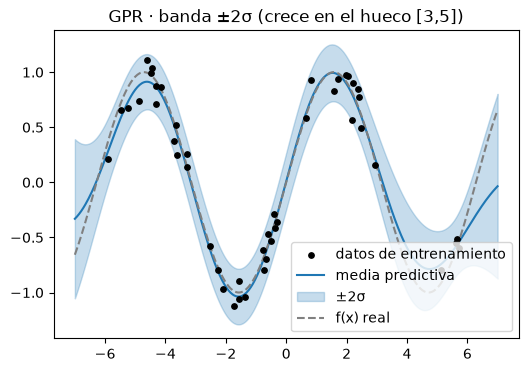

In [5]:
x_train, y_train_seno, x_malla = D.sintetico_seno1d()
y_off_s, y_sc_s = y_train_seno.mean(), y_train_seno.std()
modelo_1d = pipeline_gpr(kernel=kernel_rbf()).named_steps["clf"]
modelo_1d.fit(x_train, (y_train_seno - y_off_s) / y_sc_s)
media_malla_std, sigma_malla_std = modelo_1d.predict(x_malla, return_std=True)
media_malla = media_malla_std * y_sc_s + y_off_s
sigma_malla = sigma_malla_std * y_sc_s

G.banda_gpr_1d(x_train, y_train_seno, x_malla, media_malla, sigma_malla, "04_gpr_banda_seno.png",
               "GPR · banda ±2σ (crece en el hueco [3,5])", y_real=np.sin(x_malla.ravel()))
plt.show()


In [6]:
y_real_test = np.sin(x_malla.ravel())
cobertura = cobertura_intervalo(y_real_test, media_malla, sigma_malla)
print(f"cobertura de la banda ±2σ sobre la malla: {cobertura:.2%} (objetivo ~95%)")


cobertura de la banda ±2σ sobre la malla: 100.00% (objetivo ~95%)


## Comparación de núcleos

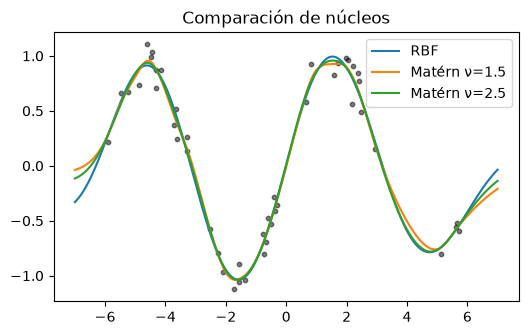

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for nombre, kernel in [("RBF", kernel_rbf()), ("Matérn ν=1.5", kernel_matern(nu=1.5)), ("Matérn ν=2.5", kernel_matern(nu=2.5))]:
    m = pipeline_gpr(kernel=kernel).named_steps["clf"]
    m.fit(x_train, (y_train_seno - y_off_s) / y_sc_s)
    media_k, _ = m.predict(x_malla, return_std=True)
    ax.plot(x_malla, media_k * y_sc_s + y_off_s, label=nombre)
ax.scatter(x_train, y_train_seno, s=10, color="k", alpha=0.5)
ax.legend()
ax.set_title("Comparación de núcleos")
plt.savefig("../reports/figuras/04_gpr_nucleos.png", dpi=150, bbox_inches="tight")
plt.show()


## Costo computacional: curva con tamaños crecientes (O(n³))

n=  50  tiempo de ajuste=0.052s
n= 100  tiempo de ajuste=0.075s
n= 200  tiempo de ajuste=0.115s


n= 400  tiempo de ajuste=0.754s


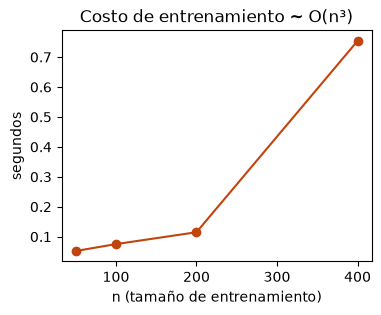

In [8]:
import time

tamanos = [50, 100, 200, 400]
tiempos = []
for n in tamanos:
    inicio = time.perf_counter()
    pipeline_gpr().named_steps["clf"].fit(diabetes.X_train[:n], y_train_std[:n])
    tiempos.append(time.perf_counter() - inicio)
    print(f"n={n:4d}  tiempo de ajuste={tiempos[-1]:.3f}s")

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(tamanos, tiempos, "o-", color="#c1440e")
ax.set_xlabel("n (tamaño de entrenamiento)"); ax.set_ylabel("segundos")
ax.set_title("Costo de entrenamiento ~ O(n³)")
plt.savefig("../reports/figuras/04_gpr_costo.png", dpi=150, bbox_inches="tight")
plt.show()


## Verificación matemática: NumPy vs `GaussianProcessRegressor` (núcleo fijo)

In [9]:
from familia3.desde_cero import ProcesoGaussianoNumPy
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

rng = np.random.default_rng(0)
X = rng.uniform(-3, 3, size=(30, 1))
y = np.sin(X).ravel() + rng.normal(0, 0.05, size=30)

propio = ProcesoGaussianoNumPy(longitud_escala=1.0, varianza=1.0, ruido=1e-6, normalize_y=True).fit(X, y)
referencia = GaussianProcessRegressor(kernel=RBF(length_scale=1.0), alpha=1e-6, normalize_y=True, optimizer=None).fit(X, y)

X_nuevo = rng.uniform(-3, 3, size=(10, 1))
media_propio, sigma_propio = propio.predict(X_nuevo)
media_ref, sigma_ref = referencia.predict(X_nuevo, return_std=True)
print("diferencia máxima en media:", np.max(np.abs(media_propio - media_ref)))
print("diferencia máxima en sigma:", np.max(np.abs(sigma_propio - sigma_ref)))
assert np.allclose(media_propio, media_ref, atol=1e-6)
print("Verificado: coincide con GaussianProcessRegressor (núcleo fijo).")


diferencia máxima en media: 6.679634623196762e-11
diferencia máxima en sigma: 1.868461982357239e-13
Verificado: coincide con GaussianProcessRegressor (núcleo fijo).
